# Behavioral Modeling Analysis

Tests whether the anisotropically-stretched prototype direction (w₂) better predicts the model's contextual log-probability boost than the plain normalized prototype direction (w₁).

Both models tilt the BOS-only vocab distribution by an episode-specific score s_m(y, S) and a fitted temperature β, evaluated via Pearson r between the predicted and observed boost on held-out support sets:

- **`full_rank_prototype` (w₁)**: direction = normalized support prototype p_S
- **`anisotropically_stretched_direction` (w₂)**: direction = p_S anisotropically stretched by the ridge map A's singular values in A's own input-direction basis

If w₂ > w₁ at the best layer → anisotropic scaling encodes behaviorally predictive information beyond what a flat prototype captures.

In [21]:
import os
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr as _pearsonr, wilcoxon as _wilcoxon

import matplotlib as mpl

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

In [22]:
SAVE_DIR    = os.path.join("Figures_Final", "summary")
os.makedirs(SAVE_DIR, exist_ok=True)

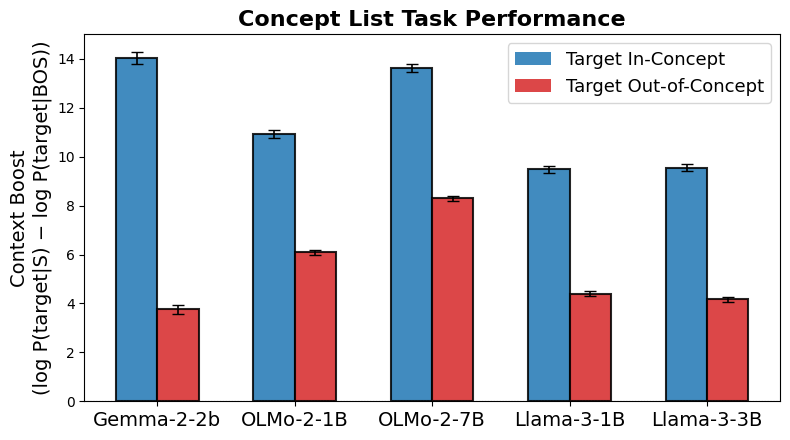

In [24]:
ALL_MODELS = [
    ("google_gemma-2-2b",         "Gemma-2-2b"),
    ("allenai_OLMo-2-0425-1B",    "OLMo-2-1B"),
    ("allenai_OLMo-2-1124-7B",    "OLMo-2-7B"),
    ("meta-llama_Llama-3.2-1B",   "Llama-3-1B"),
    ("meta-llama_Llama-3.2-3B",   "Llama-3-3B"),
]
RESULTS_ROOT = "../results_final/categories"

CONDITIONS = [
    (True,  "C0", "Target In-Concept"),
    (False, "C3", "Target Out-of-Concept"),
]

boost_data = {}
for model_safe, model_label in ALL_MODELS:
    cl_path = os.path.join(RESULTS_ROOT, model_safe, "concept_list", "default", "concept_list_behavior.csv")
    if not os.path.exists(cl_path):
        print(f"Missing: {cl_path} — skipping {model_label}")
        continue
    cl_df = pd.read_csv(cl_path)
    cat_means = (
        cl_df.groupby(["category", "target_in_category"])["context_boost"]
        .mean()
        .reset_index()
    )
    boost_data[model_safe] = cat_means

present_models = [(s, l) for s, l in ALL_MODELS if s in boost_data]
n_models = len(present_models)
n_conds  = len(CONDITIONS)
x_centers = np.arange(n_models, dtype=float)
width = 0.3
starts = np.array([-width / 2, width / 2])

fig, ax = plt.subplots(figsize=(max(6, n_models * 1.6), 4.5))

handles = []
for c_idx, (flag, color, label) in enumerate(CONDITIONS):
    positions = x_centers + starts[c_idx]
    means, sems = [], []
    for model_safe, _ in present_models:
        vals = boost_data[model_safe][boost_data[model_safe]["target_in_category"] == flag]["context_boost"]
        means.append(vals.mean())
        sems.append(vals.sem())
    ax.bar(positions, means, yerr=sems, color=color, width=width,
           alpha=0.85, capsize=4, error_kw=dict(linewidth=1.2), edgecolor="black", linewidth=1.5)
    handles.append(plt.Rectangle((0, 0), 1, 1, fc=color, alpha=0.85, label=label))


ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax.set_xticks(x_centers)
ax.set_xticklabels([l for _, l in present_models], fontsize=14)
ax.set_ylabel("Context Boost\n(log P(target|S) − log P(target|BOS))", fontsize=14)
ax.set_title("Concept List Task Performance", fontsize=16, fontweight="bold")
ax.legend(handles=handles, fontsize=13)
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "concept_list_performance.pdf"), format="pdf", bbox_inches="tight")

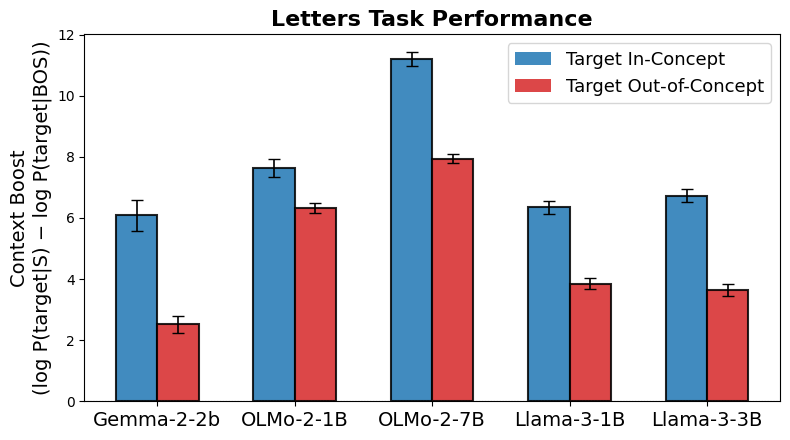

In [25]:
LETTERS_ROOT = "../results_final/letters"

boost_data_letters = {}
for model_safe, model_label in ALL_MODELS:
    cl_path = os.path.join(LETTERS_ROOT, model_safe, "concept_list", "default", "concept_list_behavior.csv")
    if not os.path.exists(cl_path):
        print(f"Missing: {cl_path} — skipping {model_label}")
        continue
    cl_df = pd.read_csv(cl_path)
    cat_means = (
        cl_df.groupby(["category", "target_in_category"])["context_boost"]
        .mean()
        .reset_index()
    )
    boost_data_letters[model_safe] = cat_means

present_models_l = [(s, l) for s, l in ALL_MODELS if s in boost_data_letters]
n_models_l = len(present_models_l)
x_centers_l = np.arange(n_models_l, dtype=float)
width = 0.3
starts = np.array([-width / 2, width / 2])

fig, ax = plt.subplots(figsize=(max(6, n_models_l * 1.6), 4.5))

handles = []
for c_idx, (flag, color, label) in enumerate(CONDITIONS):
    positions = x_centers_l + starts[c_idx]
    means, sems = [], []
    for model_safe, _ in present_models_l:
        vals = boost_data_letters[model_safe][boost_data_letters[model_safe]["target_in_category"] == flag]["context_boost"]
        means.append(vals.mean())
        sems.append(vals.sem())
    ax.bar(positions, means, yerr=sems, color=color, width=width,
           alpha=0.85, capsize=4, error_kw=dict(linewidth=1.2), edgecolor="black", linewidth=1.5)
    handles.append(plt.Rectangle((0, 0), 1, 1, fc=color, alpha=0.85, label=label))

ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
ax.set_xticks(x_centers_l)
ax.set_xticklabels([l for _, l in present_models_l], fontsize=14)
ax.set_ylabel("Context Boost\n(log P(target|S) − log P(target|BOS))", fontsize=14)
ax.set_title("Letters Task Performance", fontsize=16, fontweight="bold")
ax.legend(handles=handles, fontsize=13)
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "letters_concept_list_performance.pdf"), format="pdf", bbox_inches="tight")

## Leave-one-concept-out (LOCO) analysis

For each concept, both the direction **and** the temperature β are refit using only every *other* concept's train rows. The held-out rows of the left-out concept are then scored with this entirely held-out direction+temperature, giving a clean unseen-concept generalization test.

`anisotropically_stretched_direction_loco` additionally swaps in that concept's own LOCO ridge map (from `latent_regressions.py`), so the direction itself is also never seen.

Pooled statistics (aggregate Pearson r across all LOCO concepts) are reported in `summary.json`; `loco_per_concept.csv` holds each concept's individual (small-n, noisy) r.

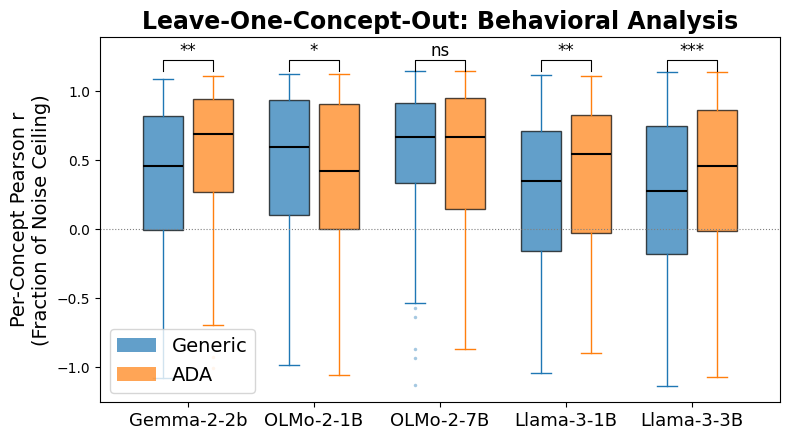

In [27]:
ALL_MODELS = [
    ("google_gemma-2-2b",         "Gemma-2-2b"),
    ("allenai_OLMo-2-0425-1B",    "OLMo-2-1B"),
    ("allenai_OLMo-2-1124-7B",    "OLMo-2-7B"),
    ("meta-llama_Llama-3.2-1B",   "Llama-3-1B"),
    ("meta-llama_Llama-3.2-3B",   "Llama-3-3B"),
]
RESULTS_ROOT = "../results_final/categories"

LOCO_TYPES = [
    ("full_rank_prototype_loco",                 "C0", "Generic"),
    ("anisotropically_stretched_direction_loco", "C1", "ADA"),
]

loco_data = {}
for model_safe, model_label in ALL_MODELS:
    loco_path = os.path.join(RESULTS_ROOT, model_safe, "behavioral_modeling", "loco_per_concept.csv")
    pred_path = os.path.join(RESULTS_ROOT, model_safe, "behavioral_modeling", "predictions.csv")
    if not os.path.exists(loco_path):
        print(f"Missing: {loco_path} — skipping {model_label}")
        continue
    loco_df = pd.read_csv(loco_path)

    if os.path.exists(pred_path):
        pred_df = pd.read_csv(pred_path)
        first_model = pred_df["model"].iloc[0]
        heldout = pred_df[(pred_df["split"] == "heldout") & (pred_df["model"] == first_model)].copy()
        heldout["shuffled_boost"] = heldout["log_p_target_given_shuffled_context"] - heldout["log_p_target_bos"]
        global_nc = float(_pearsonr(heldout["observed_boost"], heldout["shuffled_boost"]).statistic)
        loco_df["pearson_r_normalized"] = loco_df["pearson_r"] / global_nc
    else:
        print(f"Missing predictions.csv for {model_label} — cannot normalize by noise ceiling")
        loco_df["pearson_r_normalized"] = np.nan

    loco_data[model_safe] = loco_df

if not loco_data:
    print("No loco_per_concept.csv files found — run behavioral_modeling.py with --leave_one_concept_out")
else:
    present_models = [(s, l) for s, l in ALL_MODELS if s in loco_data]
    n_models = len(present_models)
    x_centers = np.arange(n_models, dtype=float)
    offset = 0.2

    fig, ax = plt.subplots(figsize=(max(6, n_models * 1.6), 4.5))

    handles = []
    for t_idx, (loco_key, color, loco_label) in enumerate(LOCO_TYPES):
        positions = x_centers + offset * (t_idx * 2 - 1)
        data_per_model = [
            loco_data[s][loco_data[s]["model"] == loco_key]["pearson_r_normalized"].dropna().values
            for s, _ in present_models
        ]
        ax.boxplot(
            data_per_model,
            positions=positions,
            widths=0.32,
            patch_artist=True,
            medianprops=dict(color="black", linewidth=1.5),
            boxprops=dict(facecolor=color, alpha=0.7),
            whiskerprops=dict(color=color),
            capprops=dict(color=color),
            flierprops=dict(marker="o", markersize=2.5, alpha=0.4,
                            markerfacecolor=color, markeredgecolor="none"),
        )
        handles.append(plt.Rectangle((0, 0), 1, 1, fc=color, alpha=0.7, label=loco_label))

    ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")

    # Significance brackets: Stretched vs Prototype (Wilcoxon signed-rank, paired by category)
    all_data = np.concatenate([
        loco_data[s][loco_data[s]["model"].isin([k for k, *_ in LOCO_TYPES])]["pearson_r_normalized"].dropna().values
        for s, _ in present_models
    ])
    ylims = ax.get_ylim()
    bracket_y = np.nanpercentile(all_data, 98) + 0.04
    bracket_h = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.03

    for m_idx, (model_safe, _) in enumerate(present_models):
        df = loco_data[model_safe]
        pivot = df[df["model"].isin(["full_rank_prototype_loco", "anisotropically_stretched_direction_loco"])].pivot(
            index="category", columns="model", values="pearson_r_normalized"
        ).dropna()
        diff = pivot["anisotropically_stretched_direction_loco"].values - pivot["full_rank_prototype_loco"].values
        _, p = _wilcoxon(diff)
        sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
        x1 = x_centers[m_idx] - offset  # Prototype
        x2 = x_centers[m_idx] + offset  # Stretched
        ax.plot([x1, x1, x2, x2], [bracket_y, bracket_y + bracket_h, bracket_y + bracket_h, bracket_y],
                color="black", linewidth=0.8)
        ax.text((x1 + x2) / 2, bracket_y + bracket_h, sig, ha="center", va="bottom", fontsize=12)

    ax.set_xticks(x_centers)
    ax.set_ylim(ylims[0], ylims[1] *1.1)
    ax.set_xticklabels([l for _, l in present_models], fontsize=13)
    ax.set_ylabel("Per-Concept Pearson r\n(Fraction of Noise Ceiling)", fontsize=14)
    ax.set_title(
        "Leave-One-Concept-Out: Behavioral Analysis",
        fontsize=17, fontweight="bold"
    )
    ax.legend(handles=handles, fontsize=14)
    plt.tight_layout()
    plt.show()
    fig.savefig(os.path.join(SAVE_DIR, "behavioral_loco_all_models.pdf"), format="pdf", bbox_inches="tight")

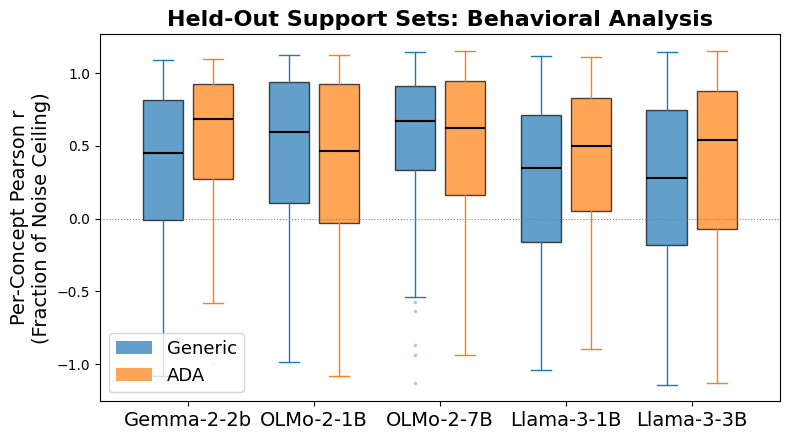

In [29]:
MODEL_TYPES = [
    ("full_rank_prototype",                 "C0", "Generic"),
    ("anisotropically_stretched_direction", "C1", "ADA"),
]

heldout_data = {}
for model_safe, model_label in ALL_MODELS:
    pred_path = os.path.join(RESULTS_ROOT, model_safe, "behavioral_modeling", "predictions.csv")
    if not os.path.exists(pred_path):
        print(f"Missing: {pred_path} — skipping {model_label}")
        continue
    pred_df = pd.read_csv(pred_path)

    # Global noise ceiling over all held-out rows at once
    first_model = pred_df["model"].iloc[0]
    heldout_all = pred_df[(pred_df["split"] == "heldout") & (pred_df["model"] == first_model)].copy()
    heldout_all["shuffled_boost"] = heldout_all["log_p_target_given_shuffled_context"] - heldout_all["log_p_target_bos"]
    global_nc = float(_pearsonr(heldout_all["observed_boost"], heldout_all["shuffled_boost"]).statistic)

    # Per-concept Pearson r for each model type on held-out rows
    heldout = pred_df[pred_df["split"] == "heldout"]
    rows = []
    for model_key, _, _ in MODEL_TYPES:
        sub = heldout[heldout["model"] == model_key]
        for cat, grp in sub.groupby("category"):
            if len(grp) >= 2:
                r, _ = _pearsonr(grp["observed_boost"], grp["predicted_boost"])
            else:
                r = np.nan
            rows.append({"model": model_key, "category": cat,
                         "pearson_r": r, "pearson_r_normalized": r / global_nc})
    heldout_data[model_safe] = pd.DataFrame(rows)

present_models = [(s, l) for s, l in ALL_MODELS if s in heldout_data]
n_models = len(present_models)
x_centers = np.arange(n_models, dtype=float)
offset = 0.2

fig, ax = plt.subplots(figsize=(max(6, n_models * 1.6), 4.5))

handles = []
for t_idx, (model_key, color, label) in enumerate(MODEL_TYPES):
    positions = x_centers + offset * (t_idx * 2 - 1)
    data_per_model = [
        heldout_data[s][heldout_data[s]["model"] == model_key]["pearson_r_normalized"].dropna().values
        for s, _ in present_models
    ]
    ax.boxplot(
        data_per_model,
        positions=positions,
        widths=0.32,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=1.5),
        boxprops=dict(facecolor=color, alpha=0.7),
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker="o", markersize=2.5, alpha=0.4,
                        markerfacecolor=color, markeredgecolor="none"),
    )
    handles.append(plt.Rectangle((0, 0), 1, 1, fc=color, alpha=0.7, label=label))

ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")

ax.set_xticks(x_centers)
ax.set_xticklabels([l for _, l in present_models], fontsize=14)
ax.set_ylabel("Per-Concept Pearson r\n(Fraction of Noise Ceiling)", fontsize=14)
ax.set_title("Held-Out Support Sets: Behavioral Analysis", fontsize=16, fontweight="bold")
ax.legend(handles=handles, fontsize=13)
plt.tight_layout()
plt.show()
fig.savefig(os.path.join(SAVE_DIR, "behavioral_heldout_all_models.pdf"), format="pdf", bbox_inches="tight")